In [1]:

from pathlib import Path
import yaml, sys
import numpy as np
from datetime import datetime
import os
os.environ["JAX_PLATFORMS"] = "cpu"
import keypoint_moseq as kpms


## Setup

In [2]:


# input dir
dlc_dir = "./DLC_Skilled_reaching-Raphael-2026-10-14"
raw_video_dir = "./data/BetaMouv/keypoint_moseq/dlc_data"

# output dir
stamp = datetime.now().strftime("%Y_%m_%d")
project_dir = f"./data/BetaMouv/keypoint_moseq/{stamp}_v2"
# os.mkdir(project_dir)

project_info_path = "./config/BetaMouv/project_info.yaml"
with open(project_info_path, "r") as f: 
    cfg = yaml.safe_load(f) 


In [3]:
bodyparts_to_use = [
    "Hand_base",
    "Base_finger_2",
    "Base_finger_3",
    "Phalanx_1_finger_2",
    "Phalanx_1_finger_3",
    "finger_1",
    "finger_2",
    "finger_3",
    "soft_pad",
    "Front_PAD_corner",
    "Back_PAD_corner",
    # "Lever_ball",
    # "Lever_base",
    # "Lever_corner",
]

anterior_bp = ["Front_PAD_corner"]
posterior_bp = ["Back_PAD_corner"]

In [25]:
config = lambda: kpms.load_config(project_dir)

dlc_config = "./DLC_Skilled_reaching-Raphael-2026-10-14/config.yaml"
kpms.setup_project(project_dir, deeplabcut_config=dlc_config, overwrite=True)

print("update_config")
kpms.update_config(
    project_dir,
    video_dir=raw_video_dir,
    anterior_bodyparts=anterior_bp,
    posterior_bodyparts=posterior_bp,
    use_bodyparts=bodyparts_to_use,
    fps=cfg["fps"],
)

kpms.update_config(
    project_dir,
    fps=125,
    fix_heading=False,          # try True as a test (see below)
    ar_hypparams={"nlags": 6,           # 3 is only 24 ms at 125 fps
                  "latent_dim": 8},     # replace with PCA-based value (see below)
    trans_hypparams={"num_states": 8,  # 100 is far too many for ~6,300 frames
                     "kappa": 1e2},     # placeholder, set by the scan
)

update_config


In [26]:
config = lambda: kpms.load_config(project_dir)
print(config()["ar_hypparams"], config()["trans_hypparams"])

{'latent_dim': 8, 'nlags': 6} {'kappa': 100.0, 'num_states': 8}


## Load keypoints and remove outlier

In [6]:
print("load keypoints from deeplabcut")

# # load data (e.g. from DeepLabCut)
dlc_filenames = list(Path(raw_video_dir).rglob("*.csv"))
dlc_filenames = [file.as_posix() for file in dlc_filenames]
print(len(dlc_filenames), "files will be processed from", raw_video_dir)

coordinates, confidences, bodyparts = kpms.load_keypoints(dlc_filenames, "deeplabcut")

print("Total frames:", sum(len(seq) for seq in coordinates.values()))
print("Number of sequences:", len(coordinates))
print("Sequence lengths:", [len(seq) for seq in coordinates.values()])

kpms.update_config(project_dir, outlier_scale_factor=6.0)


load keypoints from deeplabcut
201 files will be processed from ./data/BetaMouv/keypoint_moseq/dlc_data


Loading keypoints:   0%|                        | 0/201 [00:00<?, ?it/s]

Loading keypoints: 100%|█████████████| 201/201 [00:00<00:00, 304.15it/s]

Total frames: 12663
Number of sequences: 201
Sequence lengths: [63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63, 63]


In [7]:
print("remove outlier")

coordinates, confidences = kpms.outlier_removal(
    coordinates,
    confidences,
    project_dir,
    overwrite=False,
    **config(), 
)


remove outlier


## Format data and fit PCA

In [8]:
print("format data")

# format data
data, metadata = kpms.format_data(coordinates, confidences, **config())


format data


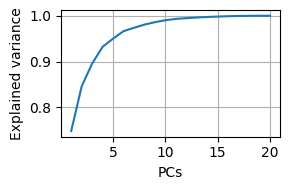

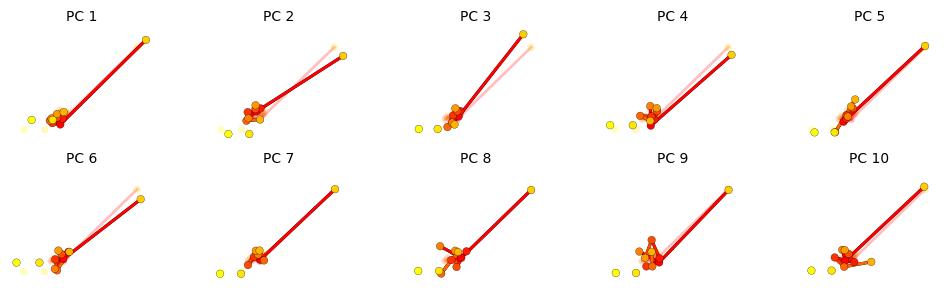

In [9]:
# run pca
pca = kpms.fit_pca(**data, **config())
kpms.save_pca(pca, project_dir)

kpms.plot_scree(pca, project_dir=project_dir)
kpms.plot_pcs(pca, project_dir=project_dir, **config())

# use the following to load an already fit model
# pca = kpms.load_pca(project_dir)



In [10]:
kpms.print_dims_to_explain_variance(pca, 0.9)
cumvar = np.cumsum(pca.explained_variance_ratio_)
latent_dim = int(np.searchsorted(cumvar, 0.90) + 1)
print("latent_dim for 90% variance:", latent_dim)

>=90.0% of variance exlained by 4 components.
latent_dim for 90% variance: 4


In [27]:
kpms.update_config(project_dir, latent_dim=latent_dim)
kpms.update_config(
    project_dir,
    sigmasq_loc=kpms.estimate_sigmasq_loc(data["Y"], data["mask"], filter_size=config()["fps"])
)
kpms.update_config(
    project_dir,
    ar_hypparams=dict(
        K_0_scale=10.0,
        S_0_scale=0.01,
        latent_dim=8,        # replace with the PCA-based value
        nlags=latent_dim,
    ),
    trans_hypparams=dict(
        alpha=5.7,
        gamma=1000.0,
        kappa=1e3,           # placeholder, the scan overrides it
        num_states=8,
    ),
)


## Kappa search

Fitting model with kappa=1000.0
Outputs will be saved to
./data/BetaMouv/keypoint_moseq/2026_10_28/my_kappa_scan-1000.0


 49%|█████████████████▏                 | 25/51 [00:04<00:06,  4.10it/s]

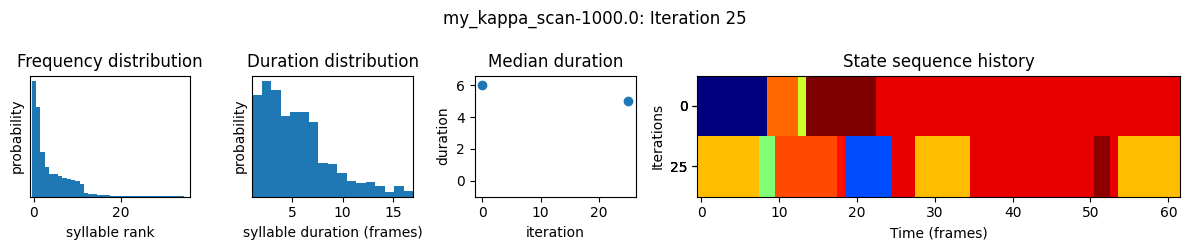

 98%|██████████████████████████████████▎| 50/51 [00:10<00:00,  5.99it/s]

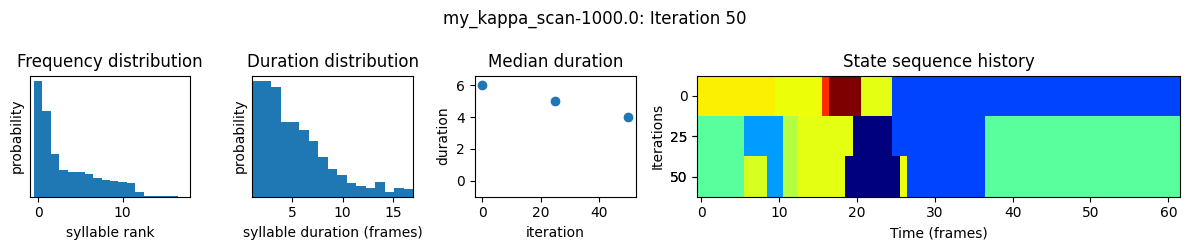

100%|███████████████████████████████████| 51/51 [00:10<00:00,  4.65it/s]


Outputs will be saved to
./data/BetaMouv/keypoint_moseq/2026_10_28/my_kappa_scan-1000.0


 17%|█████▋                            | 25/151 [00:12<01:01,  2.05it/s]

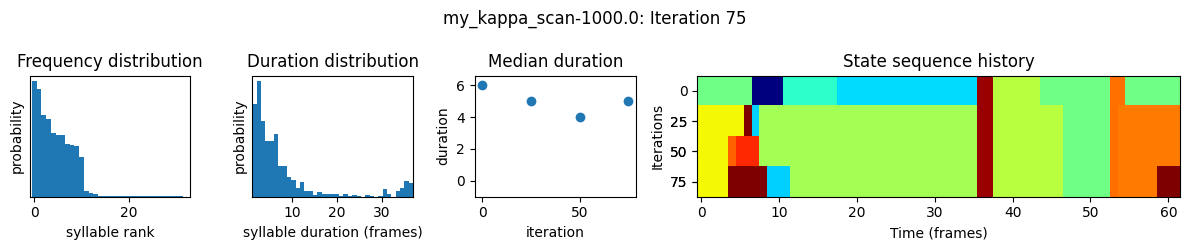

 33%|███████████▎                      | 50/151 [00:25<00:49,  2.06it/s]

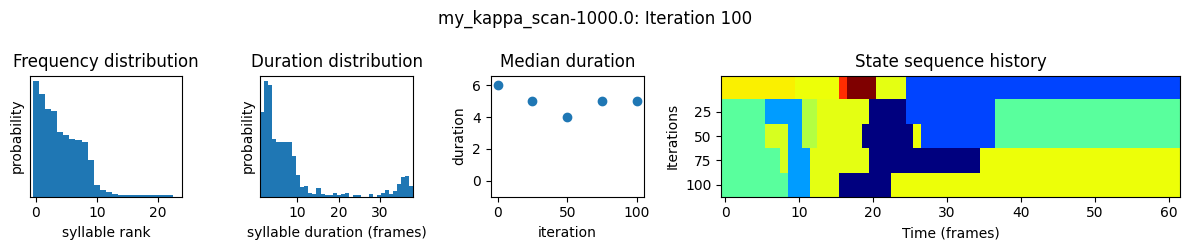

 50%|████████████████▉                 | 75/151 [00:37<00:36,  2.07it/s]

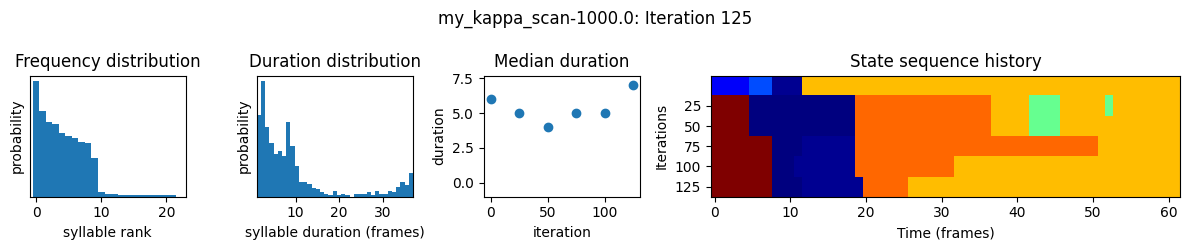

 66%|█████████████████████▊           | 100/151 [00:51<00:25,  1.97it/s]

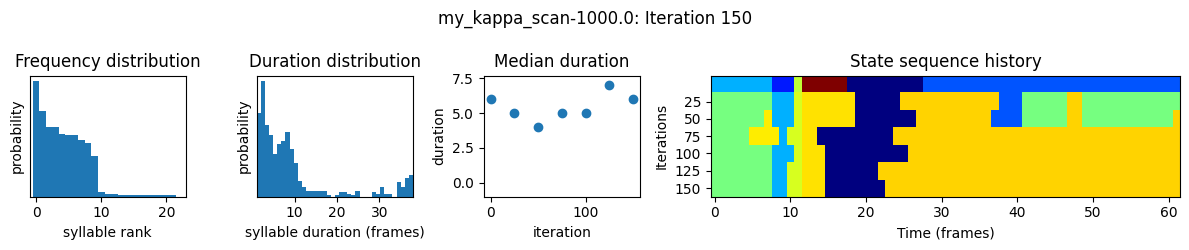

 83%|███████████████████████████▎     | 125/151 [01:04<00:12,  2.08it/s]

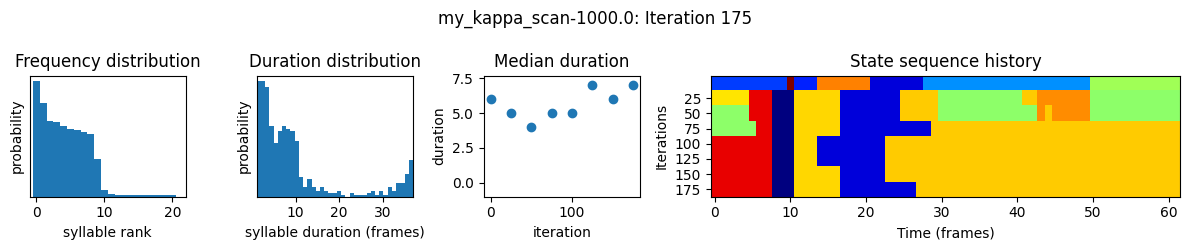

 99%|████████████████████████████████▊| 150/151 [01:16<00:00,  2.10it/s]

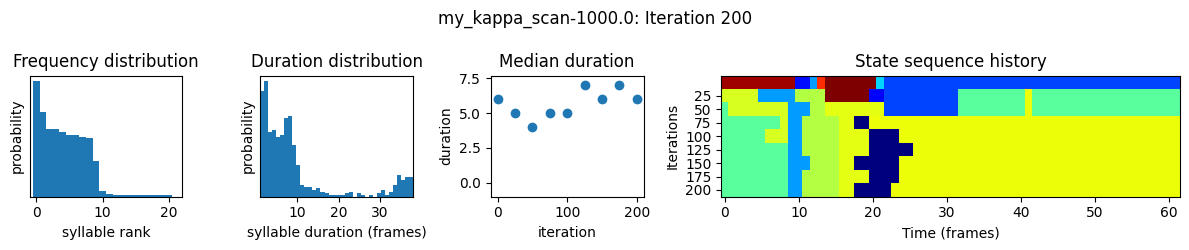

100%|█████████████████████████████████| 151/151 [01:17<00:00,  1.94it/s]


Fitting model with kappa=10000.0
Outputs will be saved to
./data/BetaMouv/keypoint_moseq/2026_10_28/my_kappa_scan-10000.0


 49%|█████████████████▏                 | 25/51 [00:05<00:04,  6.00it/s]

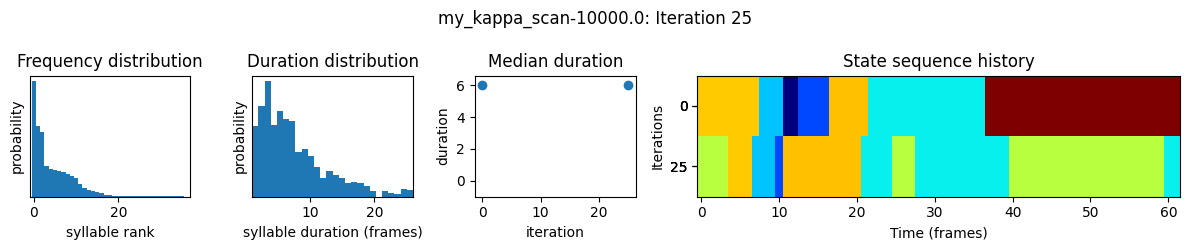

 98%|██████████████████████████████████▎| 50/51 [00:10<00:00,  6.11it/s]

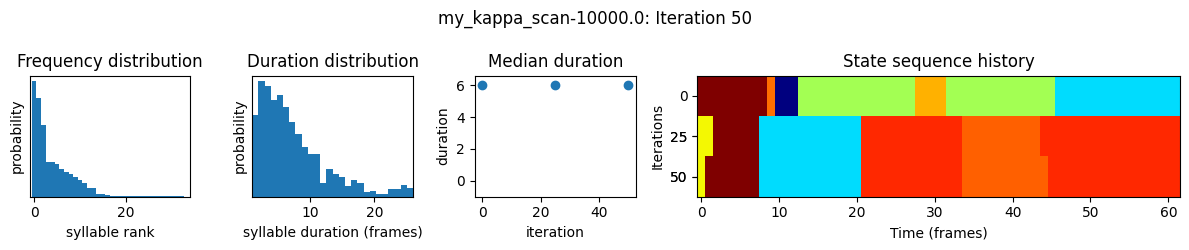

100%|███████████████████████████████████| 51/51 [00:10<00:00,  4.77it/s]


Outputs will be saved to
./data/BetaMouv/keypoint_moseq/2026_10_28/my_kappa_scan-10000.0


 17%|█████▋                            | 25/151 [00:12<01:00,  2.08it/s]

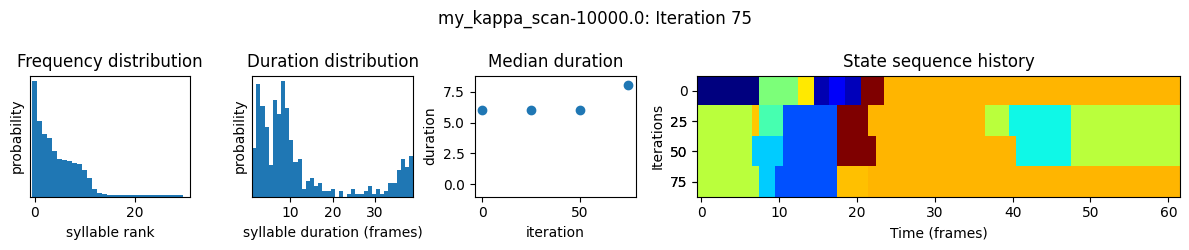

 33%|███████████▎                      | 50/151 [00:24<00:48,  2.08it/s]

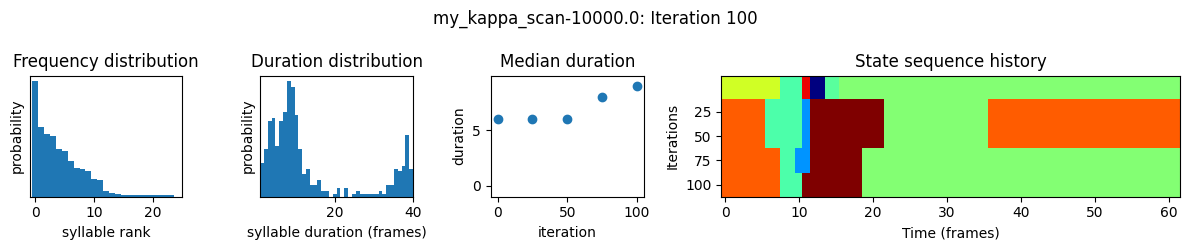

 50%|████████████████▉                 | 75/151 [00:37<00:36,  2.08it/s]

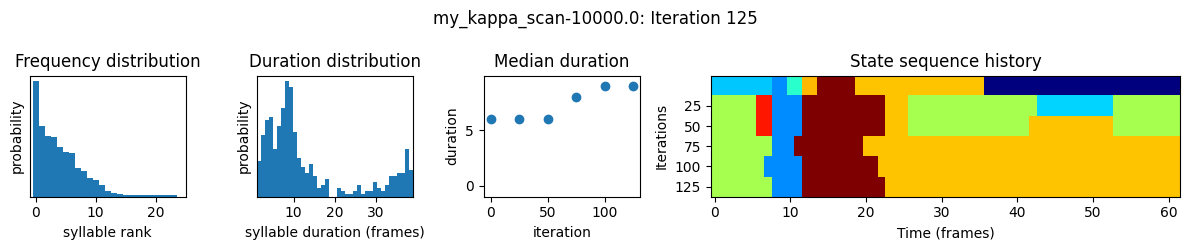

 66%|█████████████████████▊           | 100/151 [00:50<00:25,  1.99it/s]

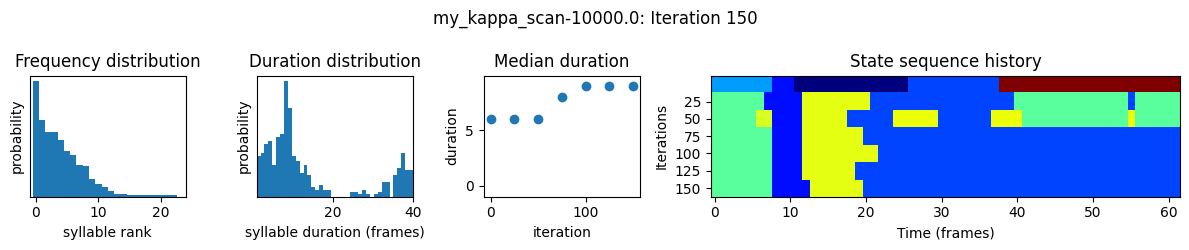

 83%|███████████████████████████▎     | 125/151 [01:03<00:13,  1.90it/s]

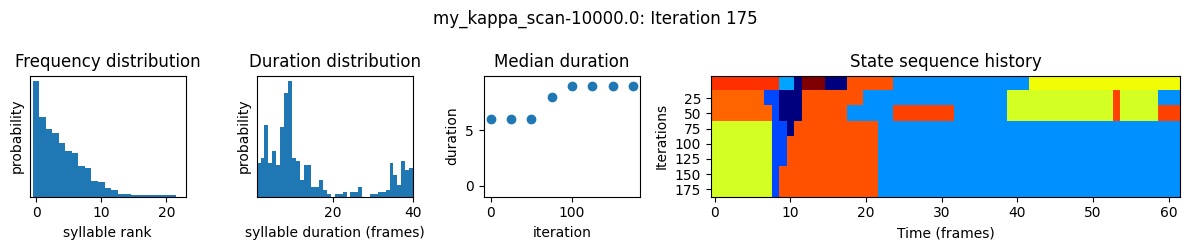

 99%|████████████████████████████████▊| 150/151 [01:16<00:00,  2.07it/s]

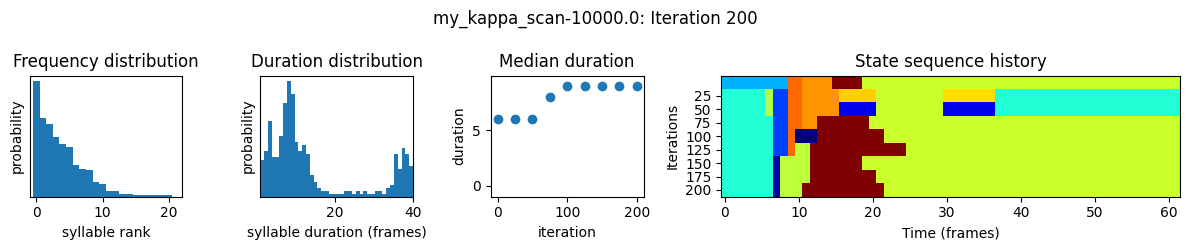

100%|█████████████████████████████████| 151/151 [01:17<00:00,  1.94it/s]


Fitting model with kappa=100000.0
Outputs will be saved to
./data/BetaMouv/keypoint_moseq/2026_10_28/my_kappa_scan-100000.0


 49%|█████████████████▏                 | 25/51 [00:04<00:05,  5.03it/s]

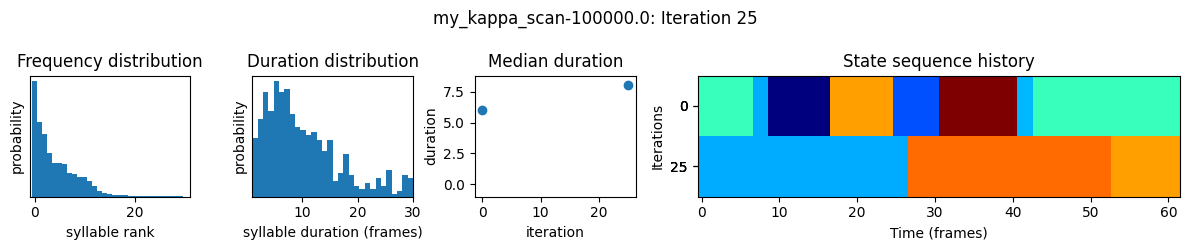

 98%|██████████████████████████████████▎| 50/51 [00:10<00:00,  4.33it/s]

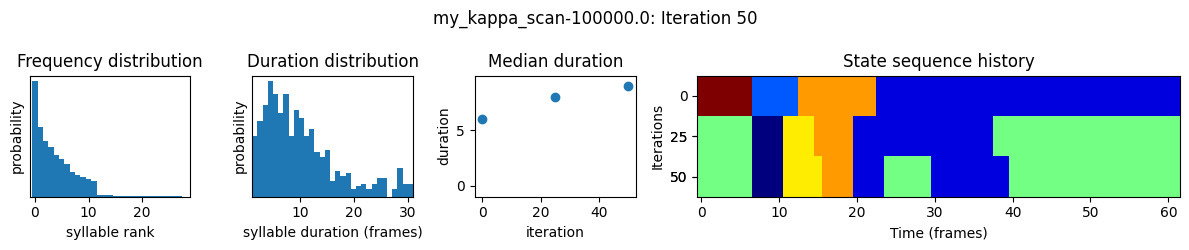

100%|███████████████████████████████████| 51/51 [00:11<00:00,  4.63it/s]


Outputs will be saved to
./data/BetaMouv/keypoint_moseq/2026_10_28/my_kappa_scan-100000.0


 17%|█████▋                            | 25/151 [00:12<01:02,  2.01it/s]

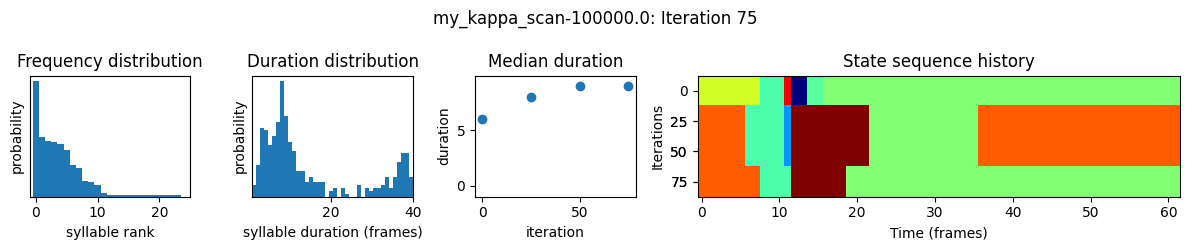

 33%|███████████▎                      | 50/151 [00:25<00:50,  2.01it/s]

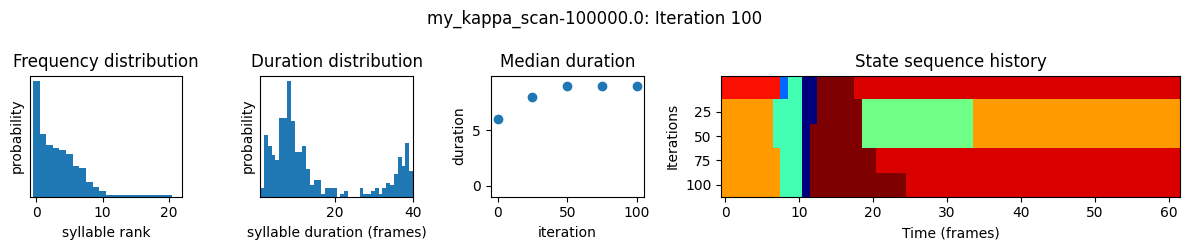

 50%|████████████████▉                 | 75/151 [00:38<00:35,  2.12it/s]

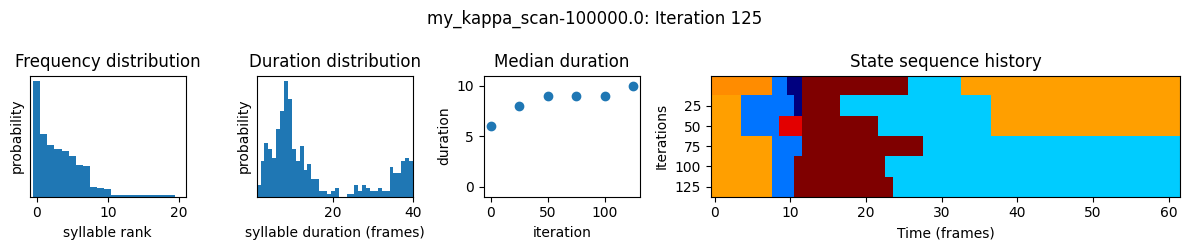

 66%|█████████████████████▊           | 100/151 [00:51<00:24,  2.12it/s]

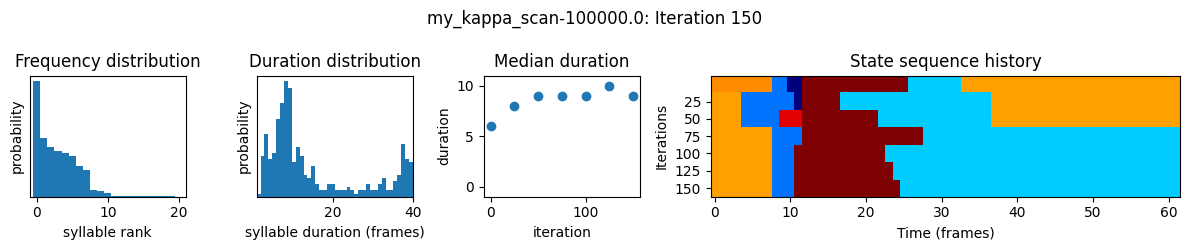

 83%|███████████████████████████▎     | 125/151 [01:04<00:12,  2.09it/s]

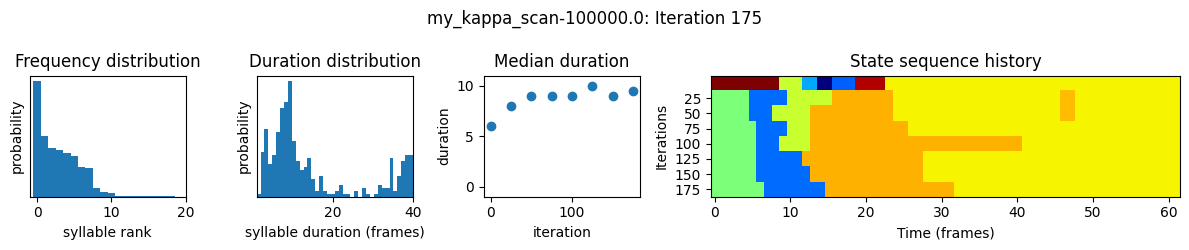

 99%|████████████████████████████████▊| 150/151 [01:17<00:00,  2.03it/s]

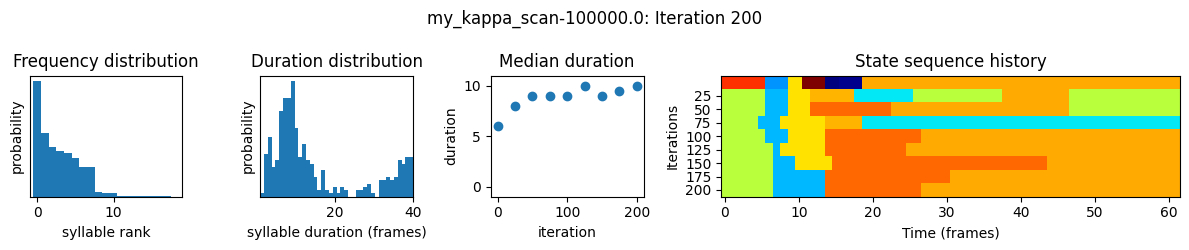

100%|█████████████████████████████████| 151/151 [01:18<00:00,  1.92it/s]


Fitting model with kappa=1000000.0
Outputs will be saved to
./data/BetaMouv/keypoint_moseq/2026_10_28/my_kappa_scan-1000000.0


 49%|█████████████████▏                 | 25/51 [00:04<00:04,  5.88it/s]

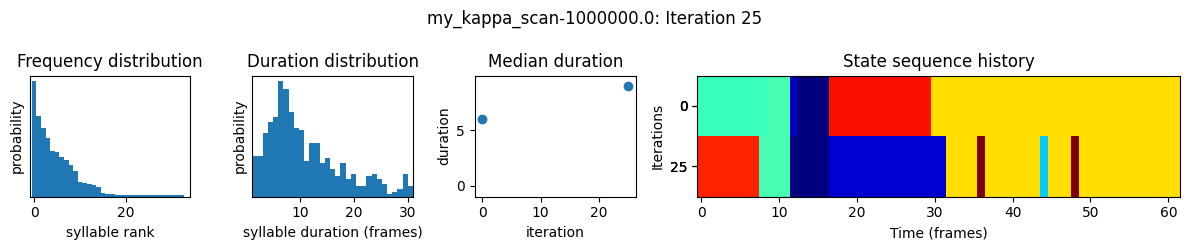

 98%|██████████████████████████████████▎| 50/51 [00:09<00:00,  6.26it/s]

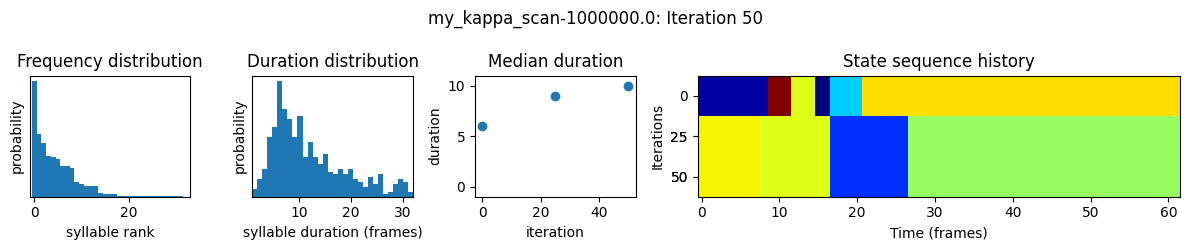

100%|███████████████████████████████████| 51/51 [00:16<00:00,  3.05it/s]


Outputs will be saved to
./data/BetaMouv/keypoint_moseq/2026_10_28/my_kappa_scan-1000000.0


 17%|█████▋                            | 25/151 [00:13<01:01,  2.06it/s]

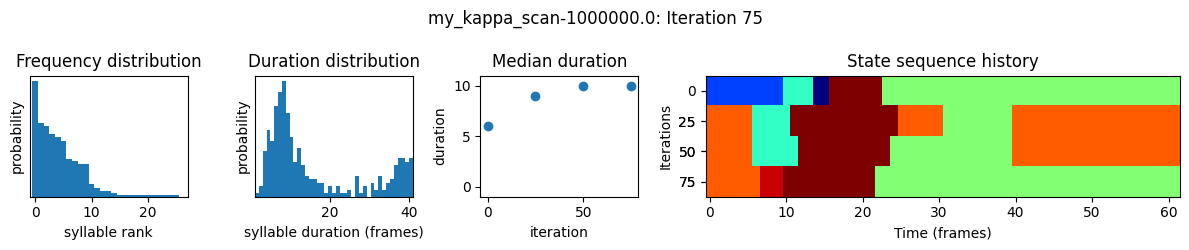

 33%|███████████▎                      | 50/151 [00:26<00:49,  2.02it/s]

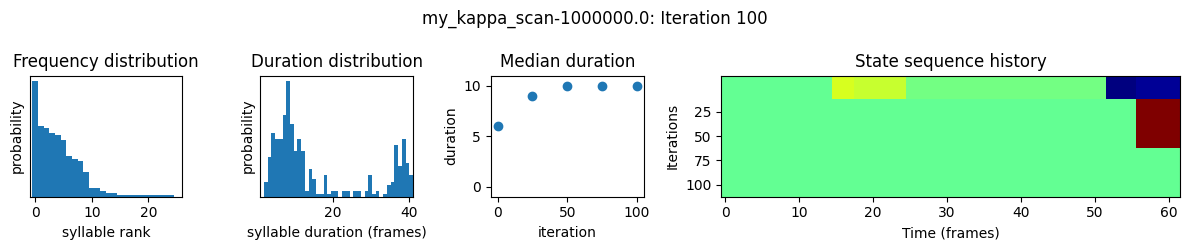

 50%|████████████████▉                 | 75/151 [00:38<00:35,  2.13it/s]

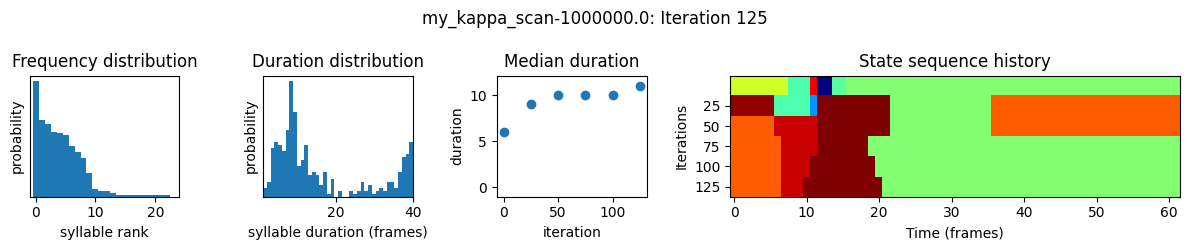

 66%|█████████████████████▊           | 100/151 [00:51<00:25,  2.02it/s]

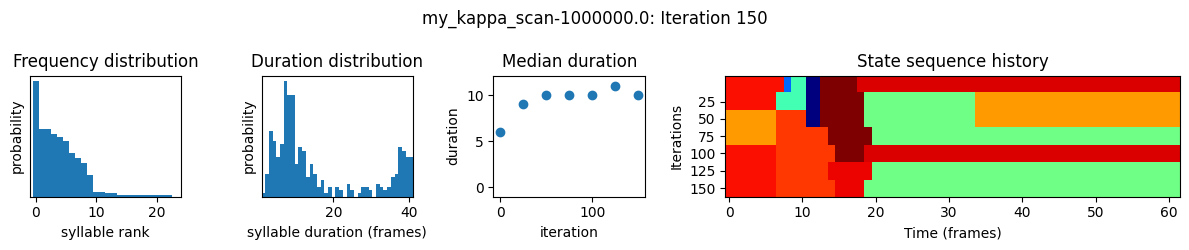

 83%|███████████████████████████▎     | 125/151 [01:04<00:15,  1.69it/s]

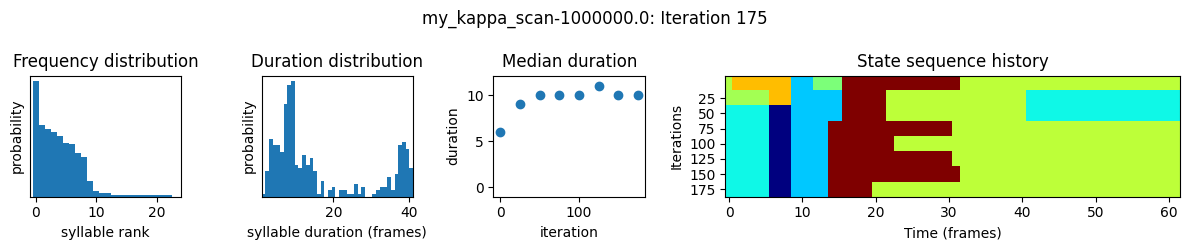

 99%|████████████████████████████████▊| 150/151 [01:17<00:00,  2.01it/s]

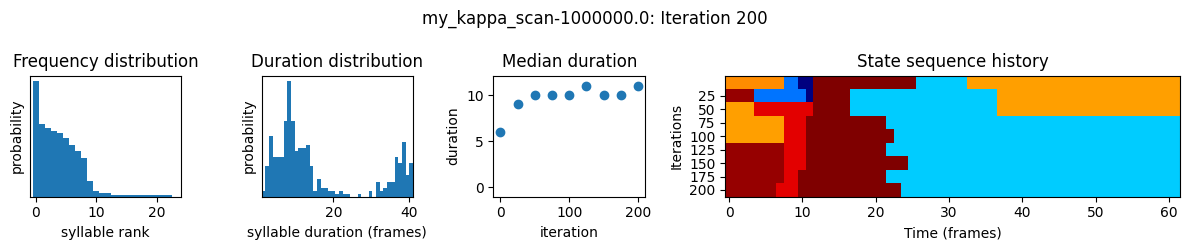

100%|█████████████████████████████████| 151/151 [01:18<00:00,  1.91it/s]


Fitting model with kappa=10000000.0
Outputs will be saved to
./data/BetaMouv/keypoint_moseq/2026_10_28/my_kappa_scan-10000000.0


 49%|█████████████████▏                 | 25/51 [00:04<00:04,  5.65it/s]

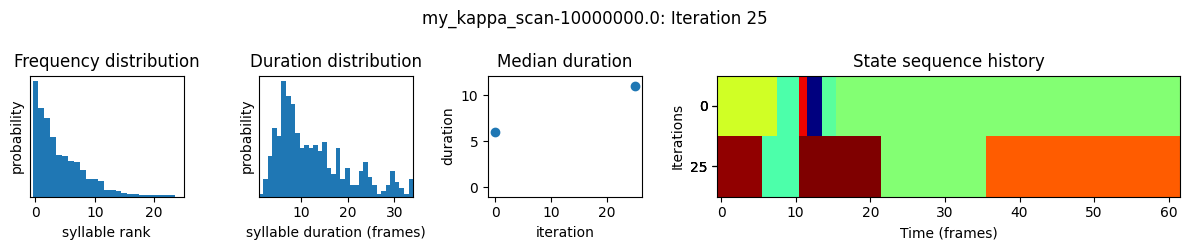

 98%|██████████████████████████████████▎| 50/51 [00:09<00:00,  6.37it/s]

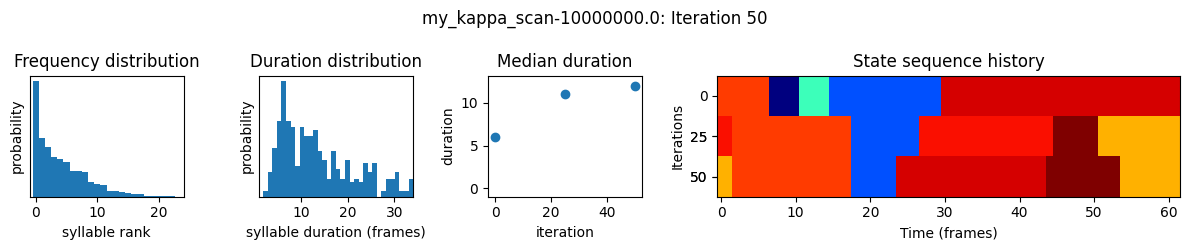

100%|███████████████████████████████████| 51/51 [00:10<00:00,  4.97it/s]


Outputs will be saved to
./data/BetaMouv/keypoint_moseq/2026_10_28/my_kappa_scan-10000000.0


 17%|█████▋                            | 25/151 [00:12<01:05,  1.93it/s]

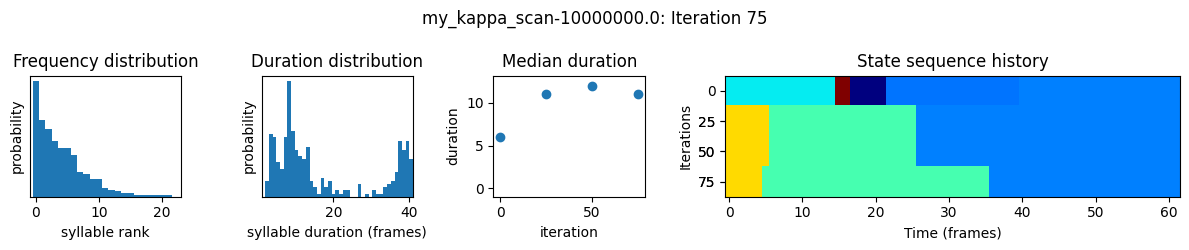

 33%|███████████▎                      | 50/151 [00:26<00:51,  1.98it/s]

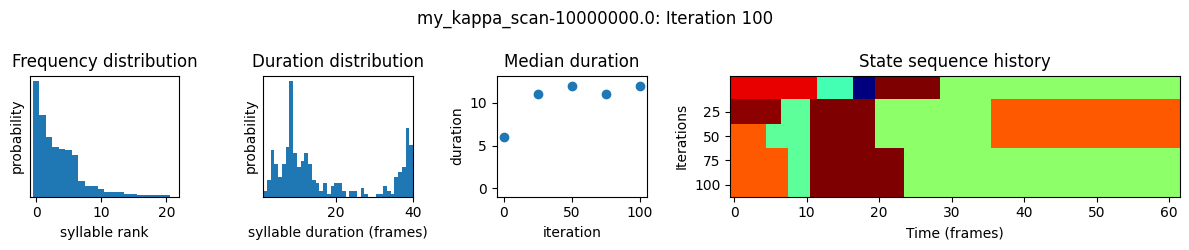

 50%|████████████████▉                 | 75/151 [00:40<00:39,  1.92it/s]

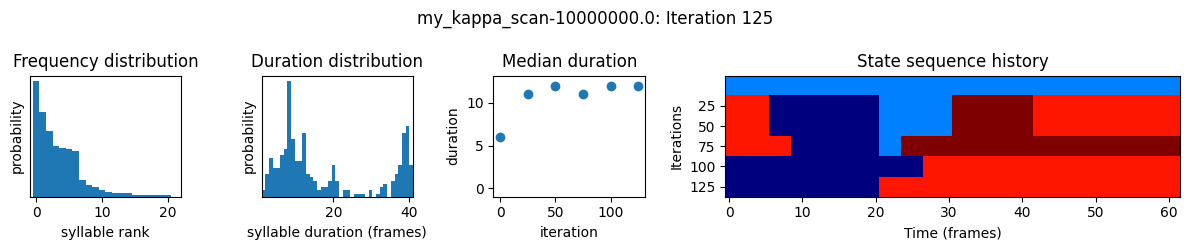

 66%|█████████████████████▊           | 100/151 [00:54<00:25,  1.98it/s]

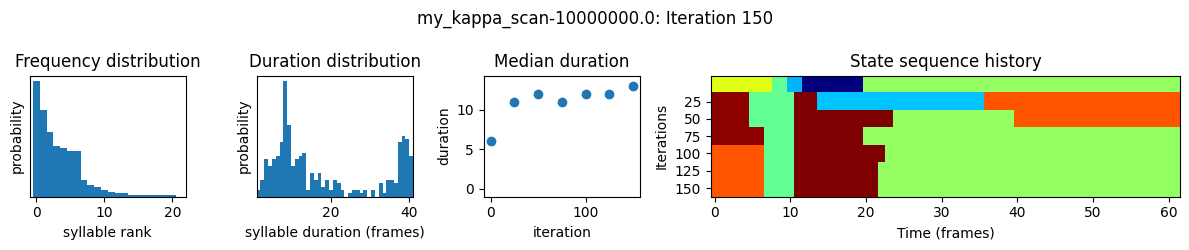

 83%|███████████████████████████▎     | 125/151 [01:08<00:13,  1.88it/s]

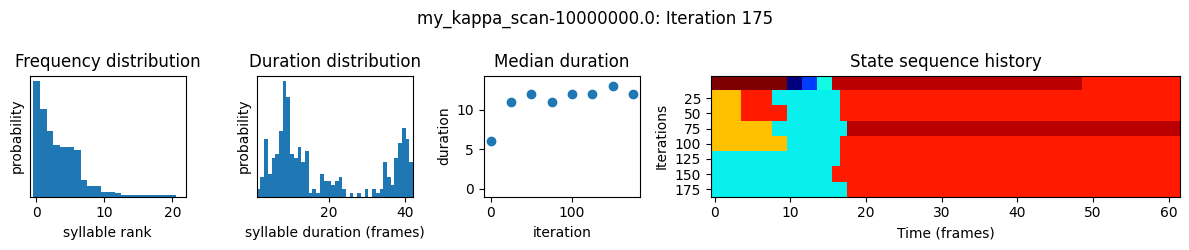

 99%|████████████████████████████████▊| 150/151 [01:21<00:00,  2.03it/s]

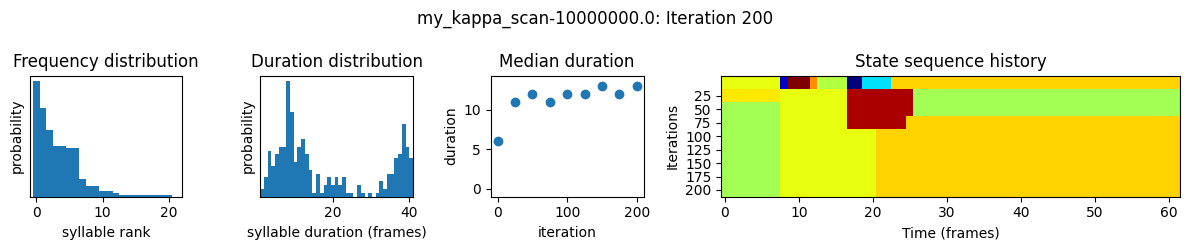

Loading checkpoints: 100%|██████████| 5/5 [00:00<00:00, 217.80it/s]


(<Figure size 800x250 with 2 Axes>, array([ 6.,  9., 10., 11., 13.]))

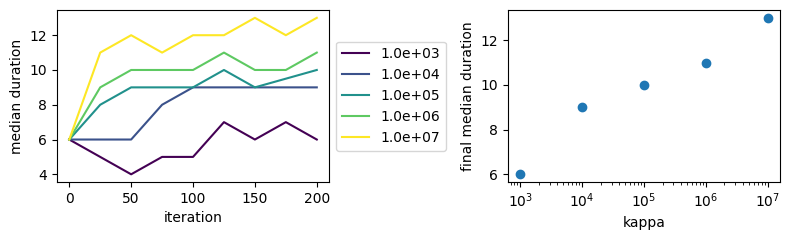

In [51]:
kappas = np.logspace(3,7,5)
decrease_kappa_factor = 10
num_ar_iters = 50
num_full_iters = 200

prefix = 'my_kappa_scan'

for kappa in kappas:
    print(f"Fitting model with kappa={kappa}")
    model_name = f'{prefix}-{kappa}'
    model = kpms.init_model(data, pca=pca, **config())

    # stage 1: fit the model with AR only
    model = kpms.update_hypparams(model, kappa=kappa)
    model = kpms.fit_model(
        model,
        data,
        metadata,
        project_dir,
        model_name,
        ar_only=True,
        num_iters=num_ar_iters,
        save_every_n_iters=25
    )[0];

    # stage 2: fit the full model
    model = kpms.update_hypparams(model, kappa=kappa/decrease_kappa_factor)
    kpms.fit_model(
        model,
        data,
        metadata,
        project_dir,
        model_name,
        ar_only=False,
        start_iter=num_ar_iters,
        num_iters=num_full_iters,
        save_every_n_iters=25
    );

kpms.plot_kappa_scan(kappas, project_dir, prefix)

## Model Fit

In [28]:
config = lambda: kpms.load_config(project_dir)
print(config()["ar_hypparams"])
print(config()["trans_hypparams"])

{'K_0_scale': 10.0, 'S_0_scale': 0.01, 'latent_dim': 8, 'nlags': 4}
{'alpha': 5.7, 'gamma': 1000.0, 'kappa': 1000.0, 'num_states': 8}


Outputs will be saved to
./data/BetaMouv/keypoint_moseq/2026_10_28_v2/final_model


 49%|█████████████████▏                 | 25/51 [00:04<00:02,  9.79it/s]

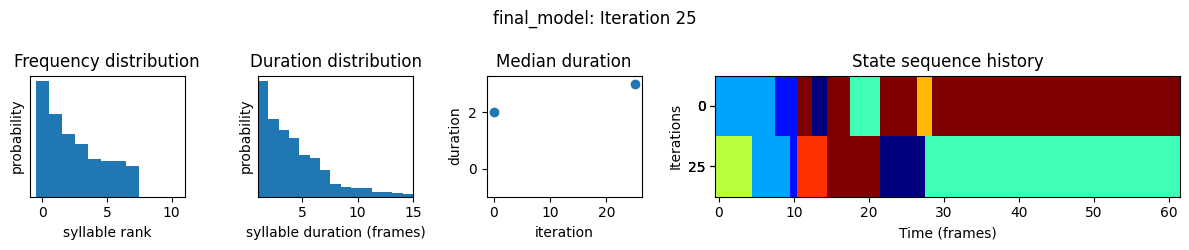

 96%|█████████████████████████████████▋ | 49/51 [00:07<00:00, 10.96it/s]

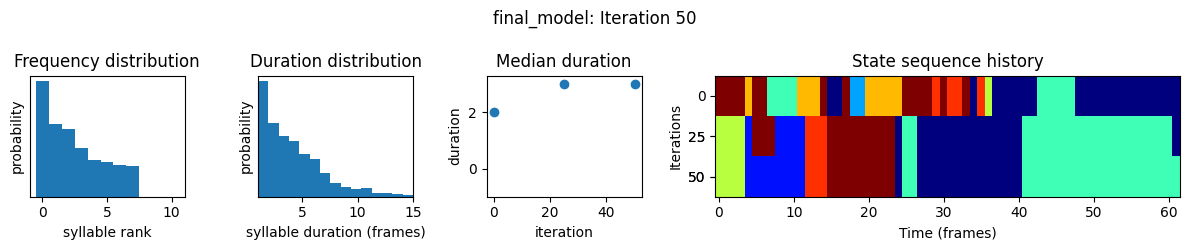

100%|███████████████████████████████████| 51/51 [00:08<00:00,  6.23it/s]


Outputs will be saved to
./data/BetaMouv/keypoint_moseq/2026_10_28_v2/final_model


  6%|█▉                                | 25/451 [01:21<18:01,  2.54s/it]

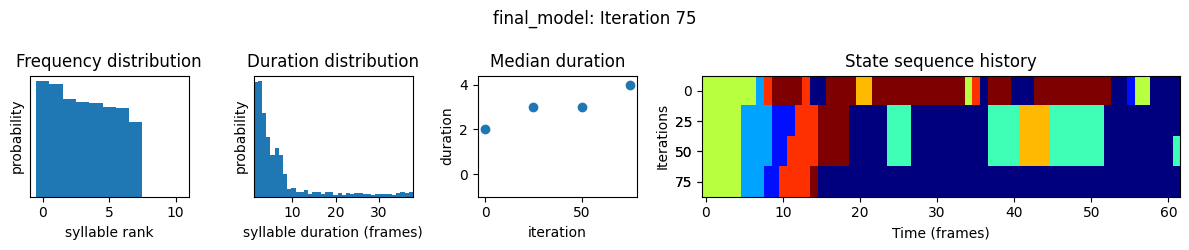

 11%|███▊                              | 50/451 [02:24<16:45,  2.51s/it]

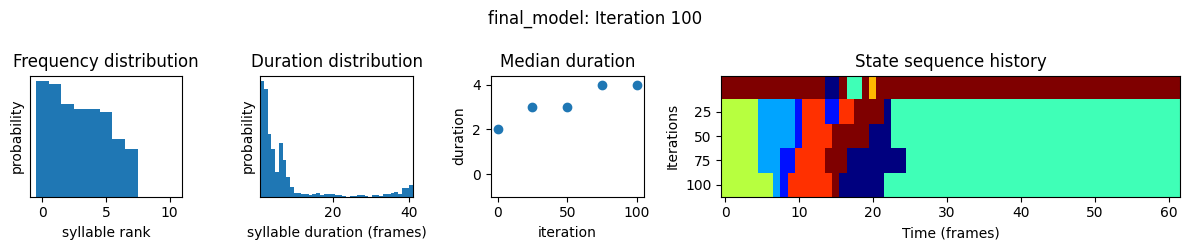

 17%|█████▋                            | 75/451 [03:28<15:16,  2.44s/it]

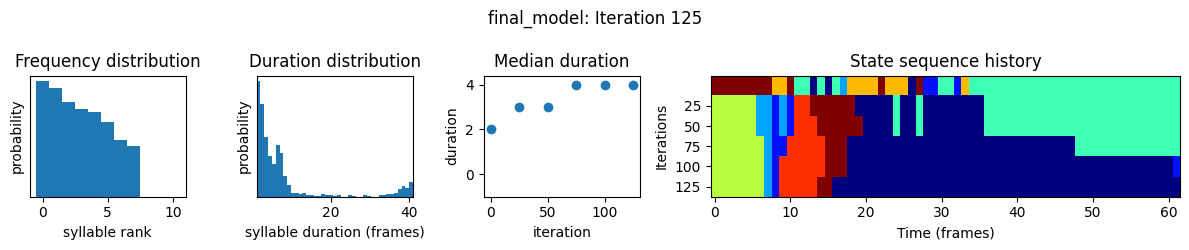

 22%|███████▎                         | 100/451 [04:34<16:44,  2.86s/it]

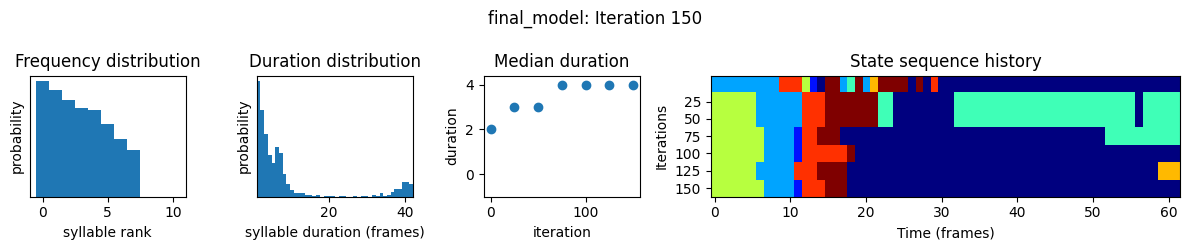

 28%|█████████▏                       | 125/451 [05:37<13:47,  2.54s/it]

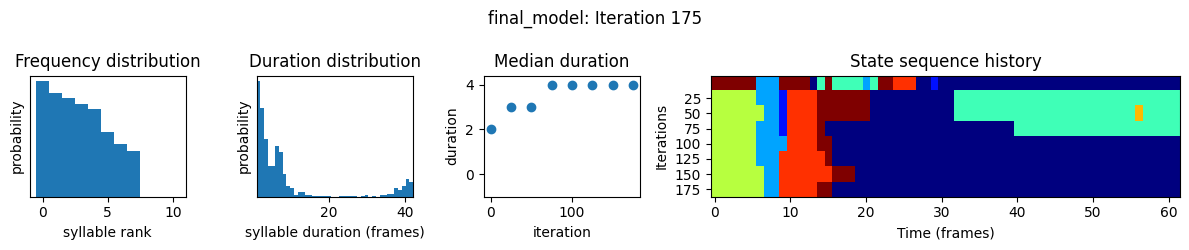

 33%|██████████▉                      | 150/451 [06:48<14:18,  2.85s/it]

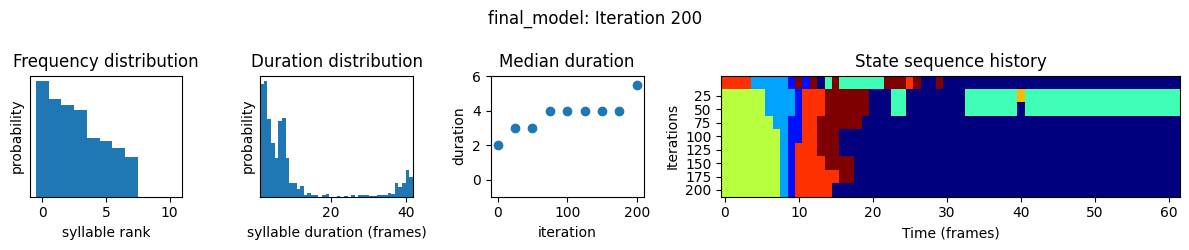

 39%|████████████▊                    | 175/451 [07:52<11:26,  2.49s/it]

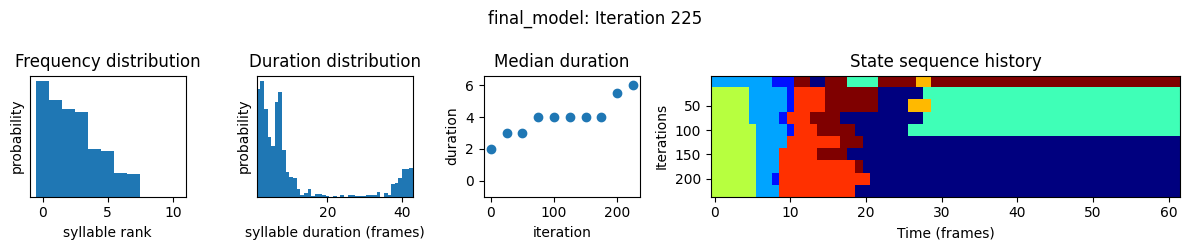

 44%|██████████████▋                  | 200/451 [08:57<10:53,  2.60s/it]

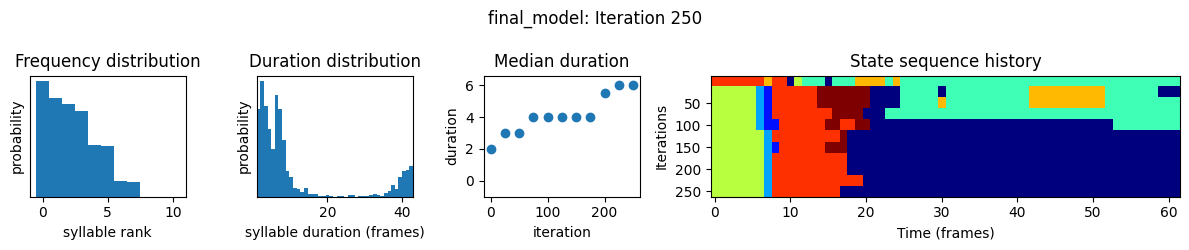

 50%|████████████████▍                | 225/451 [10:01<09:19,  2.48s/it]

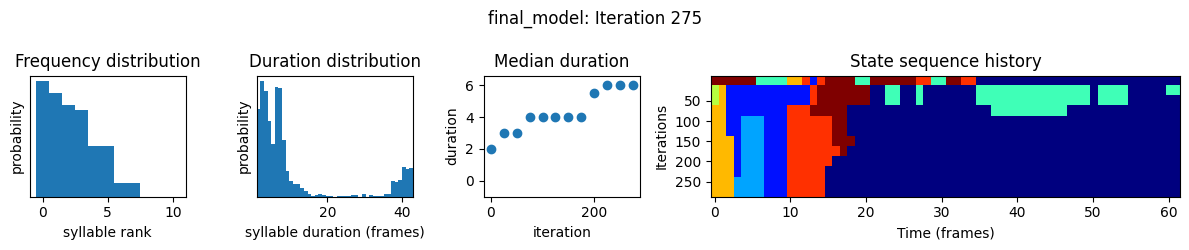

 55%|██████████████████▎              | 250/451 [11:05<08:31,  2.55s/it]

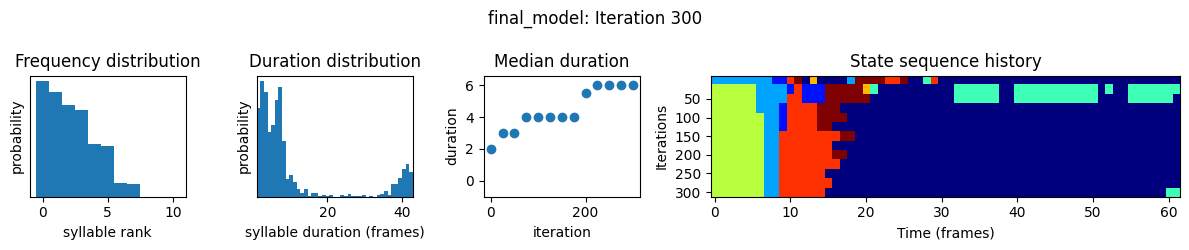

 61%|████████████████████             | 275/451 [12:09<07:14,  2.47s/it]

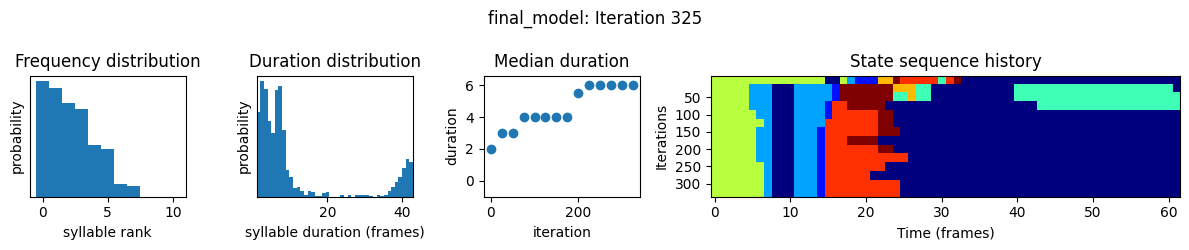

 67%|█████████████████████▉           | 300/451 [13:14<06:24,  2.55s/it]

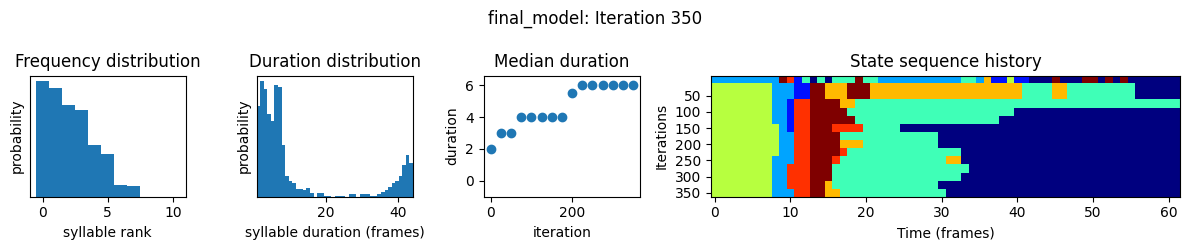

 72%|███████████████████████▊         | 325/451 [14:18<05:15,  2.51s/it]

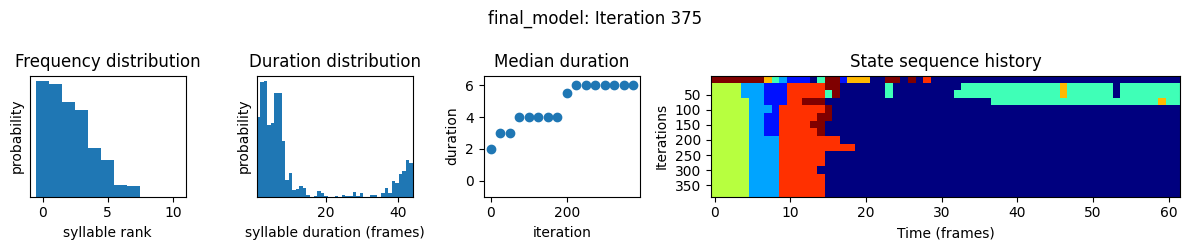

 78%|█████████████████████████▌       | 350/451 [15:21<04:11,  2.49s/it]

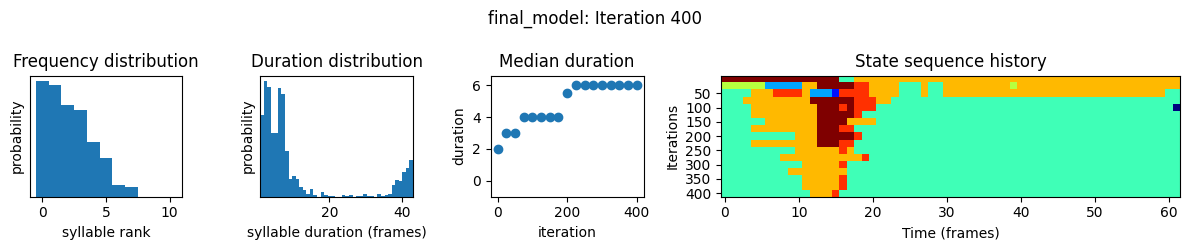

 83%|███████████████████████████▍     | 375/451 [16:25<03:13,  2.54s/it]

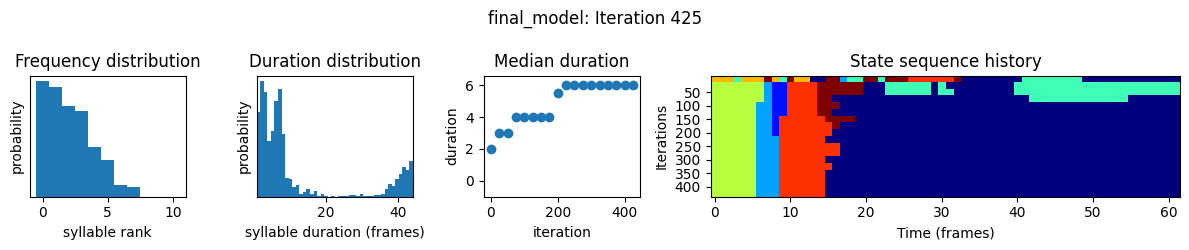

 89%|█████████████████████████████▎   | 400/451 [17:32<02:24,  2.84s/it]

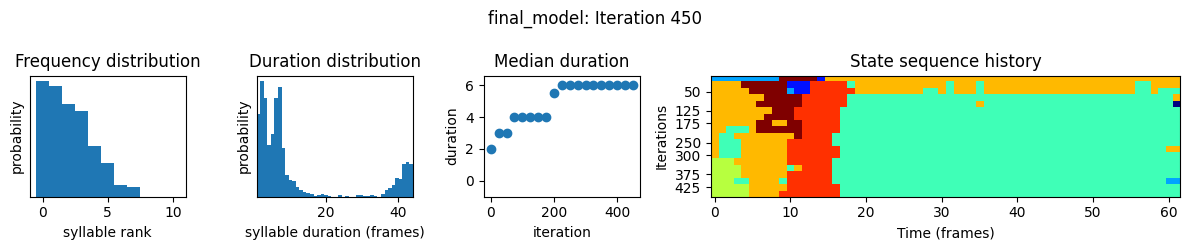

 94%|███████████████████████████████  | 425/451 [18:37<01:09,  2.66s/it]

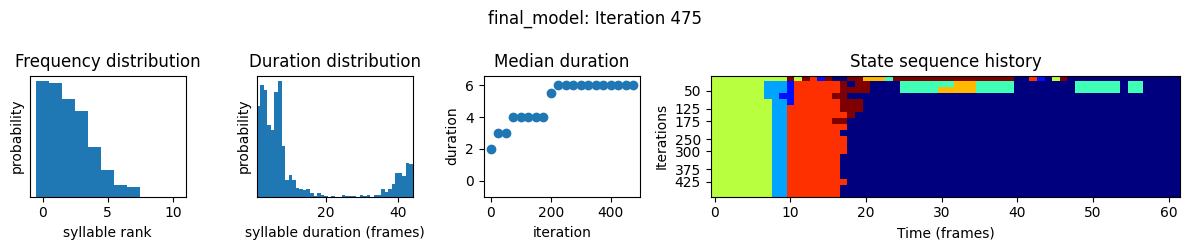

100%|████████████████████████████████▉| 450/451 [19:41<00:02,  2.56s/it]

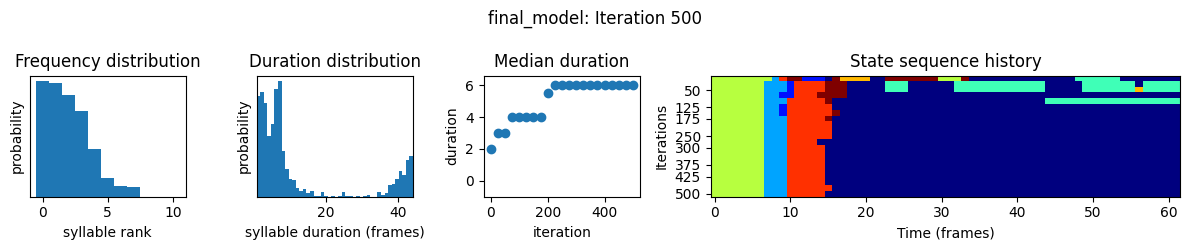

100%|█████████████████████████████████| 451/451 [19:44<00:00,  2.63s/it]


({'seed': Array([ 334076032, 1920628323], dtype=uint32),
  'states': {'h': Array([[ 0.29234642, -0.37591699,  1.2455415 , ..., -0.30770212,
           -0.34045945, -0.26411259],
          [-0.37783416,  1.38880238,  3.08626113, ..., -0.27043617,
           -0.33561643, -0.36365793],
          [-0.4503238 ,  2.54579142,  2.91240163, ..., -0.35818211,
           -0.26023475, -0.2896205 ],
          ...,
          [-0.62338775, -0.59610929,  0.19165164, ..., -0.25730501,
           -0.23019282, -0.36614719],
          [-0.57444534, -0.05448189, -0.30444198, ..., -0.36217133,
           -0.24638279, -0.25506378],
          [-0.14255477, -0.06730548, -0.10964921, ..., -0.31461335,
           -0.23007607, -0.21537778]], dtype=float64),
   's': Array([[[1.69329533e+01, 3.81168062e+03, 3.49548556e+02, ...,
            8.12825022e+03, 2.66322184e+03, 4.30919590e+03],
           [2.80912994e+01, 1.50513737e+03, 1.17441397e+01, ...,
            5.94393609e+02, 1.54252529e+03, 2.78999797e+03],
   

In [29]:
best_kappa = 1e3   # replace with your pick

model = kpms.init_model(data, pca=pca, **config())
model = kpms.update_hypparams(model, kappa=best_kappa)
model = kpms.fit_model(model, data, metadata, project_dir, "final_model",
                       ar_only=True, num_iters=50)[0]

model = kpms.update_hypparams(model, kappa=best_kappa / 10)
kpms.fit_model(model, data, metadata, project_dir, "final_model",
               ar_only=False, start_iter=50, num_iters=500,
               save_every_n_iters=25)

## Extract results

In [31]:
model_name = "final_model"
print(model_name)

final_model


In [32]:
print("extract model results")

# extract model results
# load the most recent model checkpoint
model, data, metadata, current_iter = kpms.load_checkpoint(project_dir, model_name)

# extract results
results = kpms.extract_results(model, metadata, project_dir, model_name)
kpms.save_results_as_csv(results, project_dir, model_name)


extract model results
Saved results to
./data/BetaMouv/keypoint_moseq/2026_10_28_v2/final_model/results.h5


Saving to csv: 100%|█████████████████| 201/201 [00:00<00:00, 279.99it/s]


### Load model if already existing

In [26]:
print("loading model results")

# model_name = "2026_10_22-17_07_15"

results = kpms.load_results(project_dir, model_name)
model, data, metadata, current_iter = kpms.load_checkpoint(project_dir, model_name)
print("Loaded iteration:", current_iter)
print("Number of recordings:", len(results))

# Load the original keypoint coordinates
coordinates, confidences, bodyparts = kpms.load_keypoints(
    dlc_filenames,
    "deeplabcut"
)

loading model results
Loaded iteration: 550
Number of recordings: 100


Loading keypoints: 100%|█████████████| 100/100 [00:00<00:00, 199.60it/s]


### Display results

display results


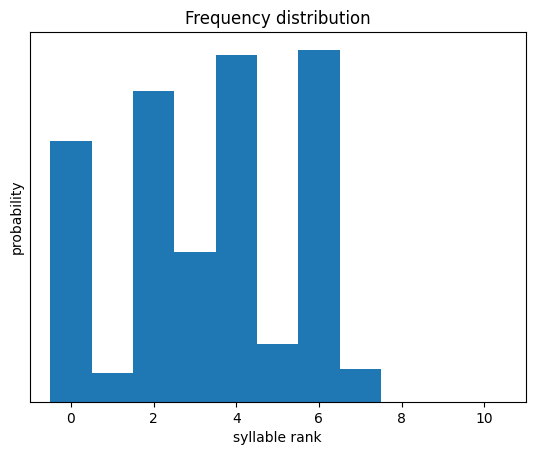

In [33]:

print("display results")

fig, ax = kpms.plot_syllable_frequencies(project_dir, model_name, results)


In [34]:
from collections import Counter
syllable_counts = Counter()

for trial, res in results.items():
    syllables = np.asarray(res["syllable"]).ravel()
    syllable_counts.update(syllables.tolist())

print("Total unique syllables:", len(syllable_counts))
print("Total syllable counts:")

for syllable, count in sorted(syllable_counts.items()):
    print(f"Syllable {syllable}: {count} frames")

Total unique syllables: 8
Total syllable counts:
Syllable 0: 6411 frames
Syllable 1: 41 frames
Syllable 2: 447 frames
Syllable 3: 1985 frames
Syllable 4: 1996 frames
Syllable 5: 161 frames
Syllable 6: 1595 frames
Syllable 7: 27 frames


In [43]:
import inspect
print(inspect.signature(kpms.get_syllable_instances))

(stateseqs, min_duration=3, pre=30, post=60, min_frequency=0, min_instances=0)


In [38]:
stateseqs = {
    trial: res["syllable"]
    for trial, res in results.items()
}

instances = kpms.get_syllable_instances(
    stateseqs,
    min_duration=3,
    pre=5,
    post=10,
    min_frequency=0,
    min_instances=0
)

for syllable, occurrences in sorted(instances.items()):
    print(f"Syllable {syllable}: {len(occurrences)} instances")

Syllable 0: 156 instances
Syllable 1: 5 instances
Syllable 2: 79 instances
Syllable 3: 71 instances
Syllable 4: 10 instances
Syllable 5: 18 instances
Syllable 6: 202 instances
Syllable 7: 1 instances


In [45]:

kpms.generate_trajectory_plots(coordinates, results, project_dir, model_name, 
                                min_frequency=0.00001, 
                                # density_sample=False, 
                                **config(), 
                                # sampling_options={"mode": "density", "n_neighbors": 3}
                                )

Saving trajectory plots to ./data/BetaMouv/keypoint_moseq/2026_10_28_v2/final_model/trajectory_plots


ValueError: No syllables with sufficient instances to generate a trajectory. This
usually occurs when there is not enough inut data or when all frames
have the same syllable label (use `plot_syllable_frequencies` to check
if this is the case)

In [47]:
kpms.generate_grid_movies(
    results, project_dir, model_name,
    coordinates=coordinates,
    rows=2, cols=3,        # default grid is larger
    min_frequency=0.005,
    **config(),
)

Writing grid movies to ./data/BetaMouv/keypoint_moseq/2026_10_28_v2/final_model/grid_movies


AssertionError: No matching videos found for Rat_#525Ambidexter_20240628_ContiMT300_Ri
ghtHemiCHR_L1L25050_C001H001S0003_clip_43

In [42]:
kpms.plot_similarity_dendrogram(coordinates, results, project_dir, model_name, **config())

ValueError: No syllables with sufficient instances to generate a trajectory. This
usually occurs when there is not enough inut data or when all frames
have the same syllable label (use `plot_syllable_frequencies` to check
if this is the case)